# Chapter 3 (part 2) — Multiple Testing, Degrees of Freedom, and ANOVA

Covers the middle of Ch 3 of *Practical Statistics for Data Scientists*: Multiple Testing → Degrees of Freedom → ANOVA (F-statistic, two-way ANOVA), applied to the Ames Housing dataset.

Section 1 shows what goes wrong when you run many tests, section 2 pins down a number (n-1) you've been using without a reason, and sections 3-4 extend "compare two group means" to "compare many group means at once," which is the fix for the problem section 1 exposes. Ask for a hint if you get stuck; per the repo's review protocol, the first couple of asks per question get a nudge, not the answer.

Primary tools: pandas / numpy for data wrangling, scipy.stats / statsmodels for the formal tests.

In [52]:
import numpy as np
import pandas as pd
from scipy import stats
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.formula.api import ols
import matplotlib.pyplot as plt

pd.set_option("display.max_columns", None)

ames = pd.read_csv('../data/ames_housing.csv')
ames.shape

(2930, 81)

## 1. Multiple Testing

Suppose a friend hands you a fair coin and says "I'll bet you can't find a neighborhood where houses sell for a different price than everywhere else." You don't have one in mind, so you check **every** neighborhood — 28 of them — each with its own test at alpha = 0.05.

Walk through the arithmetic first. If a test has a 5% chance of a false alarm when nothing is going on, then for one test the chance of *no* false alarm is 0.95. For two independent tests it's 0.95 x 0.95 = 0.9025. For three it's 0.95 x 0.95 x 0.95 = 0.857. Keep going to 28 tests and the chance of getting *at least one* false alarm is 1 minus that product. Before running any code, do that calculation by hand/in a cell — how likely is it that you "discover" a special neighborhood even if none exists?

Now check it with data instead of arithmetic:

1. **Simulate the problem.** Take `ames`, randomly shuffle the `Neighborhood` column so the labels are meaningless (this makes the null hypothesis true by construction: no neighborhood is truly special). For each of the 28 shuffled labels, run a test of "this label's `Sale_Price` vs. everyone else's" and record the p-value. How many of the 28 come out below 0.05? Repeat the whole shuffle-and-test-28-times procedure a few hundred times — in what fraction of repeats do you get *at least one* "significant" neighborhood? Does it match your arithmetic?
2. **Now do it on the real labels.** Run the same 28 tests with the true `Neighborhood` column. How many are significant at 0.05?
3. **Correct for it.** Apply a Bonferroni correction (divide alpha by the number of tests) and a Holm or Benjamini-Hochberg correction (`statsmodels.stats.multitest.multipletests`). How many neighborhoods survive each? Why would Bonferroni be the strictest of the three?

In [28]:
# set num of repeat iterations
repeats = 200

# copy the df and shuffle the neighborhood column
df = ames.copy()

# store repeat iteration and 1/0 if it contains at least one significant neighborhood
repeat_significance = []

for i in range(repeats):

    df["Neighborhood_Shuffled"] = np.random.permutation(df["Neighborhood"].values)

    # store p-values
    p_values = []

    # iterate through each neighborhood and perform a t-test for each label
    for neighborhood in df["Neighborhood_Shuffled"].unique():

        label_sale_price = df[df["Neighborhood_Shuffled"] == neighborhood]["Sale_Price"]
        everyone_else_price = df[df["Neighborhood_Shuffled"] != neighborhood]["Sale_Price"]

        # t-test
        res = stats.ttest_ind(label_sale_price, everyone_else_price, equal_var=False)
        p_values.append(res.pvalue)

    contains_significance = any(x < 0.05 for x in p_values)

    if contains_significance:
        repeat_significance.append(1)
    else:
        repeat_significance.append(0)

# print results
print(f"Fraction of repeats that return at least one significant neighborhood: {sum(repeat_significance)/len(repeat_significance)}")


c:\Users\Bao\Git\understand_ml_stats\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\Bao\Git\understand_ml_stats\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)
c:\Users\Bao\Git\understand_ml_stats\.venv\Lib\site-packages\scipy\stats\_axis_nan_policy.py:601: RuntimeWarning: Precision loss occurred in moment calculation due to catastrophic cancellation. This occurs when the data are nearly identical. Results may be unreliable.
  res = hypotest_fun_out(*samples, **kwds)


Fraction of repeats that return at least one significant neighborhood: 0.845


* My arithmatic results shows that the probability of an insignificant outcome it 0.95^28 which is 0.24.
* This means that the probability of getting at least one test with significant results is 1-0.24 = 0.76
* My code produced 0.805 which is fairly close to my arithmatic

In [29]:
# part 2

# store p-values and significance
p_values = []

# iterate through each neighborhood and perform a t-test for each label
for neighborhood in df["Neighborhood"].unique():

    label_sale_price = df[df["Neighborhood"] == neighborhood]["Sale_Price"]
    everyone_else_price = df[df["Neighborhood"] != neighborhood]["Sale_Price"]

    # t-test
    res = stats.ttest_ind(label_sale_price, everyone_else_price, equal_var=False)
    p_values.append(res.pvalue)

contains_significance = any(x < 0.05 for x in p_values)

significant_results = [x for x in p_values if x < 0.05]

print(f"Number of Significant Results:{len(significant_results)}")

Number of Significant Results:24


* With real labels that are unshuffled, we can see that neighborhood is a actual driver for sales price and thats why we get much higher counts of significant results.\
* Note for the future: tiny neighborhoods like greenhills(2 houses) and greens(8 houses) can make the test shaky. 
* Small groups don't make p-values dishonest but their p-values are larger becuase there's little evidence.

In [30]:
# part 3
from statsmodels.stats.multitest import multipletests
import math

# store p-values and significance
p_values = []

# iterate through each neighborhood and perform a t-test for each label
for neighborhood in df["Neighborhood"].unique():

    label_sale_price = df[df["Neighborhood"] == neighborhood]["Sale_Price"]
    everyone_else_price = df[df["Neighborhood"] != neighborhood]["Sale_Price"]

    # t-test
    res = stats.ttest_ind(label_sale_price, everyone_else_price, equal_var=False, )
    p_values.append(res.pvalue)

# remove nan caused by 1 house in landmark
p_values = [x for x in p_values if not math.isnan(x)]

# run the correction
for method in ['fdr_bh', 'holm']:
    reject, pvals_corrected, alphac_sidak, alphac_bonf = multipletests(
        p_values, 
        alpha=0.05, 
        method=method
    )

    print(f"Method: {method}")

    # significant p-value
    count = len([x for x in reject if x == True])
    print(f"Number of significant results: {count}")
    print("---------------------------------------------------------\n")

Method: fdr_bh
Number of significant results: 24
---------------------------------------------------------

Method: holm
Number of significant results: 23
---------------------------------------------------------



### Why Bonferroni (and friends) matter

**The problem in numbers.** Each test has a 5% chance of a false alarm when nothing is going on. Run 27 tests and you expect about 27 x 0.05 = 1.35 false alarms, and the chance of *at least one* is 1 - 0.95^27, roughly 75% (your section 1 simulation showed this). So "p < 0.05" stops meaning "5% chance I'm fooled" once you run many tests; the 5% applies to each test, not to the whole batch.

**Bonferroni's fix: make each test stricter so the whole batch is 5%.** Divide alpha by the number of tests: 0.05 / 27 = 0.00185. Each test now has at most a 0.185% chance of a false alarm, and 27 x 0.00185 = 0.05, so the chance of *any* false alarm across all 27 stays at about 5%. That's the whole idea: split your 5% "false alarm budget" evenly across the tests.

**The cost.** A stricter bar also rejects real differences more often (more type 2 errors). In your data, a neighborhood with p = 0.03 was "significant" at 0.05 but doesn't clear 0.00185, so it's dropped.

**The three methods you compared (alpha = 0.05, 27 tests):**

| Method | Controls | Neighborhoods significant |
|---|---|---|
| Raw p < 0.05 | nothing | 24 |
| Bonferroni | chance of *any* false alarm | 21 |
| Holm | chance of *any* false alarm (same guarantee, a bit less strict) | 23 |
| Benjamini-Hochberg (`fdr_bh`) | the *share* of your discoveries that are false | 24 |

Holm and Bonferroni protect the same thing, but Holm tests the smallest p-value against the strictest bar and relaxes the bar for each next one, so it never rejects fewer than Bonferroni. BH asks a different question: "of the neighborhoods I flag, roughly what fraction are false?" It allows about 5% of the flagged list to be wrong (about 1 of 24 here), which is why it's the most permissive of the three.

**Which to use?** If one false alarm would be costly (a medical claim, a policy decision), use Bonferroni or Holm. If you're screening many candidates and will follow up on the flagged ones anyway, BH keeps more power.

**Review notes on the code above:**
- `multipletests` already does the correcting, so pass `alpha=0.05`. Passing `0.05/27` as well divides by 27 twice. (Your BH result then matched Bonferroni's 21 by coincidence of the data.)
- `reject` is `True` where the neighborhood is significant, so the count of significant results is the number of `True` values. Your code counts the `False` ones, which is the number *not* significant (6, and 27 - 6 = 21 significant).
- The exercise asks you to compare three methods; the code runs only `fdr_bh`. Loop over `method` in `['bonferroni', 'holm', 'fdr_bh']` and compare the counts.

## 2. Degrees of Freedom

Work a tiny example by hand. Take three house prices (in $1000s): 140, 160, 210. Their mean is 170. The *deviations* from that mean are -30, -10, +40. Notice they add to zero — they always will, for any dataset, because that's what a mean is. So if I tell you the mean is 170 and the first two deviations are -30 and -10, you don't need the third number: it *has* to be +40. Only 2 of the 3 deviations were free to vary; the last was forced. That count of "values that were actually free" is the **degrees of freedom**. Hold on to that picture: here, n - 1 = 2.

Why does it matter? When you compute sample variance, you average squared deviations — but the deviations are measured from the *sample* mean, which was itself fitted to this exact sample, so it sits closer to the data than the true population mean would. The deviations come out a bit too small. Dividing by n - 1 instead of n compensates.

Test it using Ames as the "population":

1. Treat all of `Sale_Price` as the population and compute its variance with `ddof=0` (this is the true population variance).
2. Repeatedly draw small random samples (say n = 5) from `Sale_Price`, and for each one compute the sample variance two ways: dividing by n (`ddof=0`) and dividing by n - 1 (`ddof=1`). Do this several thousand times. Compare the *average* of each version to the population variance from step 1. Which one is off, in which direction?
3. Does the gap shrink if you use n = 5, 30, 200? What does that tell you about when degrees of freedom matter and when it's a rounding error?
4. Connect it to the t-test from the previous notebook: where did "degrees of freedom" show up there, and why would a t-distribution with 4 degrees of freedom have fatter tails than one with 200?

In [31]:
# part 1

# compute variance ddof = 0
var_0 = ames["Sale_Price"].var(ddof=0)
print(var_0)

6379705498.413457


In [32]:
# part 2

# variance of ddof = 0 and n-1
sampling_var_0 = []
sampling_var_n_1 = []

for i in range(5000):
    sample = ames["Sale_Price"].sample(n=5)
    sampling_var_0.append(sample.var(ddof=0))
    sampling_var_n_1.append(sample.var(ddof=1))

print(f"Average variance with df = 0: {sum(sampling_var_0)/len(sampling_var_0)}")
print(f"Average variance with df = n-1(4): {sum(sampling_var_n_1)/len(sampling_var_n_1)}")

Average variance with df = 0: 5141956670.693657
Average variance with df = n-1(4): 6427445838.367085


In [33]:
# part 3

# variance of n = 30 and 200
sampling_var_0_n_30 = []
sampling_var_0_n_200 = []
sampling_var_30 = []
sampling_var_200 = []

for i in range(5000):
    sample = ames["Sale_Price"].sample(n=30)
    sampling_var_30.append(sample.var(ddof=1))
    sampling_var_0_n_30.append(sample.var(ddof=0))

    sample_2 = ames["Sale_Price"].sample(n=200)
    sampling_var_200.append(sample_2.var(ddof=1))
    sampling_var_0_n_200.append(sample_2.var(ddof=0))

print(f"Average variance with n = 30: {sum(sampling_var_30)/len(sampling_var_30)}")
print(f"ratio n = 30 with df = n-1 against df = 0: {(sum(sampling_var_0_n_30)/len(sampling_var_0_n_30))/(sum(sampling_var_30)/len(sampling_var_30))}")
print(f"Average variance with n = 200: {sum(sampling_var_200)/len(sampling_var_200)}")
print(f"ratio n = 200 with df = n-1 against df = 0: {(sum(sampling_var_0_n_200)/len(sampling_var_0_n_200))/(sum(sampling_var_200)/len(sampling_var_200))}")

Average variance with n = 30: 6457153967.353841
ratio n = 30 with df = n-1 against df = 0: 0.966666666666668
Average variance with n = 200: 6395351517.331717
ratio n = 200 with df = n-1 against df = 0: 0.9950000000000022


**part 3 & 4**

* I believe the gap might shrink. But my thinking about this has always been, larger sample will allow for more accurate estimates to what the population estimate is.
  * **Adjustment:** the gap does shrink, but not for the reason of "more accurate estimates" alone. Two different things are happening. (1) *Noise*: a bigger sample gives a less jumpy estimate, which shrinks for every statistic. (2) *Bias*: dividing by n instead of n - 1 makes the variance too small by a fixed factor of (n - 1)/n *on average*, no matter how many repeats you average over. That's 4/5 = 0.80 at n = 5 (your 5.04e9 / 6.38e9 = 0.79), 29/30 = 0.97 at n = 30, and 199/200 = 0.995 at n = 200. The ddof gap shrinks because that factor approaches 1, not because the estimate is less noisy. (Run n = 30 and n = 200 in code to confirm; I haven't seen that output yet.)
* Degrees of freedom matter when you are using a sample to estimate something about a population.
  * **Adjustment:** more precisely, they matter when the deviations are measured from a mean that was *itself computed from the same sample*. That mean sits closer to the data than the true mean does, so one deviation is forced (the deviations must sum to 0), and only n - 1 are free. It matters a lot at n = 5 (a 20% error) and is a rounding error at n = 200 (0.5%).
* My thinking regarding the t-distributions is that low dfs might imply smaller sample sizes and therefor more uncertainty. So the t-test results account for extreme sampling error.
  * **Adjustment:** direction is right (low df = fatter tails = a bigger t-statistic is needed to be significant). The specific source of the uncertainty is that the t-test must *estimate the standard deviation from the sample too*, and with a small sample that estimate is itself noisy, as you just saw with the variance. The fatter tails pay for that. As df grows, the standard deviation estimate becomes reliable and the t-distribution converges to the normal.
  * **Missing piece (question 4's first half, where df showed up in the t-test):** in notebook 05, `ttest_ind` with equal variance uses df = n1 + n2 - 2 (one mean fitted per group, so two values lost). With `equal_var=False` (Welch, what you used), df comes from the Welch-Satterthwaite formula and is usually *not* a whole number, because it adjusts for unequal group sizes and variances. With ~700-800 houses per group, df was large either way, so the t-distribution was essentially normal.

* Df is important for small samples and irrelavent for bigger ones

## 3. ANOVA and the F-Statistic

A t-test compares two group means. What if you have five? Running every pairwise t-test brings you right back to section 1 (10 pairs = 10 chances for a false alarm). ANOVA answers one omnibus question instead: *is there any difference among these group means at all?*

The idea, with numbers: imagine three groups with these prices ($1000s): A = [100, 110, 120], B = [150, 160, 170], C = [200, 210, 220]. The grand mean is 160. Two kinds of spread exist:
- **Between-group spread:** how far each *group mean* (110, 160, 210) sits from the grand mean (160), weighted by group size. Here that's large.
- **Within-group spread:** how far the individual houses sit from *their own group's* mean (10 in every case here). That's small.

The **F-statistic** is the ratio of between-group variability to within-group variability (each divided by its own degrees of freedom). Big F = the groups differ by much more than the noise inside each group would explain. F near 1 = the group means are no more spread out than random noise would make them.

Using `Bldg_Type` (5 building types) and `Sale_Price`:

1. Plot `Sale_Price` by `Bldg_Type` (boxplot). Before running anything, which groups do you expect to differ?
2. **Compute F by hand** with pandas/numpy: sum of squares between groups, sum of squares within groups, their degrees of freedom (k - 1 and N - k — say where each comes from), and the ratio. Compare to `scipy.stats.f_oneway`.
3. **Permutation version:** shuffle the `Bldg_Type` labels, recompute F each time, and build a null distribution of F. Where does your real F fall? Does the permutation p-value agree with the F-distribution p-value?
4. ANOVA only says "not all means are equal" — it doesn't say *which*. What would you do next, and how does section 1 constrain it? (Try `statsmodels.stats.multicomp.pairwise_tukeyhsd` and say what it adjusts for.)
5. ANOVA assumes roughly equal within-group variance and roughly normal data within groups. Check both for `Bldg_Type`. Is it a concern here?

In [34]:
df = ames[["Bldg_Type","Sale_Price"]].copy()

* Before plotting I expect pretty big differences between the building types that often are attached to other homes(like dupluxes and townhouses) vs. standalone homes. 

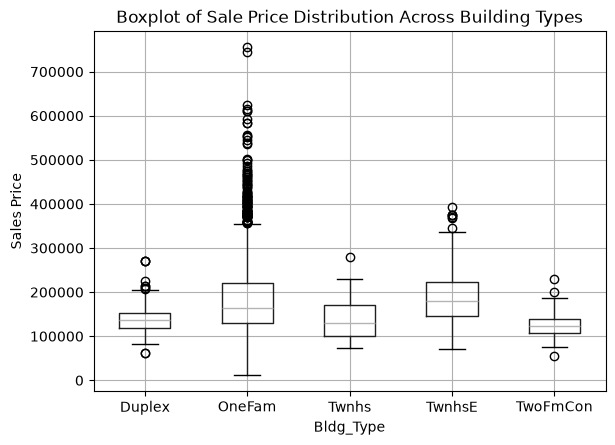

In [35]:
df.boxplot(column = "Sale_Price", by = "Bldg_Type")
plt.title("Boxplot of Sale Price Distribution Across Building Types")
plt.suptitle('')
plt.ylabel("Sales Price")
plt.show()

In [36]:
# part 2

# compute sum of squares between groups
global_mean = df["Sale_Price"].mean()
group_means = pd.DataFrame(df.groupby("Bldg_Type").agg(
    count=("Bldg_Type", "count"),
    sales_mean=("Sale_Price", "mean"),
).reset_index())
group_means["Diff_From_Global_Sqaured"] = (group_means["sales_mean"] - global_mean)**2
group_means["Multiplied_by_group_size"] = group_means["Diff_From_Global_Sqaured"] * group_means["count"]
ss_between = group_means["Multiplied_by_group_size"].sum()

# sum of squares within groups
df["group_mean"] = df.groupby("Bldg_Type")["Sale_Price"].transform("mean")
df["Diff_From_Group_Mean_Squared"] = (df["Sale_Price"] - df["group_mean"]) ** 2
ss_within = df["Diff_From_Group_Mean_Squared"].sum()

# Degrees of Freedom
# df between is k-1 where k is number of groups
df_between = len(df["Bldg_Type"].unique()) - 1
print(f"DF between groups: {df_between}")

# df within groups is N-K
df_within = len(df) - len(df["Bldg_Type"].unique())
print(f"DF within groups: {df_within}")

# mean squares between
ms_btween = ss_between/df_between
ms_within = ss_within/df_within

real_f = ms_btween/ms_within

# f-stat
print(f"F-statistic: {real_f}")


DF between groups: 4
DF within groups: 2925
F-statistic: 26.151358230905934


In [37]:
# part 3
shuffled_f = []

for i in range (5000):
    # shuffle building type label
    perm_anova_df = df.copy()
    perm_anova_df["shuffled_bldg_type"] = np.random.permutation(perm_anova_df["Bldg_Type"].values)

    # compute sum of squares between groups
    global_mean = perm_anova_df["Sale_Price"].mean()
    group_means = pd.DataFrame(perm_anova_df.groupby("shuffled_bldg_type").agg(
        count=("shuffled_bldg_type", "count"),
        sales_mean=("Sale_Price", "mean"),
    ).reset_index())
    group_means["Diff_From_Global_Sqaured"] = (group_means["sales_mean"] - global_mean)**2
    group_means["Multiplied_by_group_size"] = group_means["Diff_From_Global_Sqaured"] * group_means["count"]
    ss_between = group_means["Multiplied_by_group_size"].sum()

    # sum of squares within groups
    perm_anova_df["group_mean"] = perm_anova_df.groupby("shuffled_bldg_type")["Sale_Price"].transform("mean")
    perm_anova_df["Diff_From_Group_Mean_Squared"] = (perm_anova_df["Sale_Price"] - perm_anova_df["group_mean"]) ** 2
    ss_within = perm_anova_df["Diff_From_Group_Mean_Squared"].sum()

    # Degrees of Freedom
    # df between is k-1 where k is number of groups
    df_between = len(perm_anova_df["shuffled_bldg_type"].unique()) - 1

    # df within groups is N-K
    df_within = len(perm_anova_df) - len(perm_anova_df["shuffled_bldg_type"].unique())
  
    # mean squares between
    ms_btween = ss_between/df_between
    ms_within = ss_within/df_within

    perm_shuffle_f_stat = ms_btween/ms_within

    shuffled_f.append(perm_shuffle_f_stat)
        

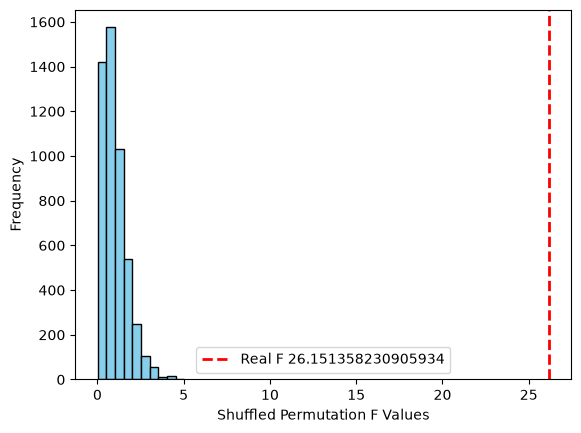

P-value: 0.0


In [40]:
# plot 
plt.hist(shuffled_f, color = "skyblue", edgecolor = 'black')
plt.axvline(real_f, color = 'red', linestyle = '--', linewidth = 2, label = f"Real F {real_f}")

# Add labels and legend
plt.xlabel('Shuffled Permutation F Values')
plt.ylabel('Frequency')
plt.legend()

# Show the plot
plt.show()

count_extreme = sum(1 for x in shuffled_f if x >= (real_f))
print(f"P-value: {count_extreme/len(shuffled_f)}")

In [39]:
# ANOVA via scipy stats
groups = [group['Sale_Price'] for name, group in df.groupby('Bldg_Type')]


f_statistic, p_value = stats.f_oneway(*groups)
print(f"F-Statistic: {f_statistic:.4f}")
print(f"p-value:     {p_value:.4e}")

F-Statistic: 26.1514
p-value:     2.4759e-21


In [41]:
# part 4 which groups differ? TukeyHSD test
from statsmodels.stats.multicomp import pairwise_tukeyhsd

result = pairwise_tukeyhsd(
    endog=df["Sale_Price"],
    groups=df["Bldg_Type"],
    alpha=0.05
)

print(result)

       Multiple Comparison of Means - Tukey HSD, FWER=0.05       
group1  group2    meandiff  p-adj     lower       upper    reject
-----------------------------------------------------------------
Duplex   OneFam  45003.1055    0.0  24011.0569   65995.154   True
Duplex    Twnhs  -3874.8764 0.9965 -33486.0996  25736.3469  False
Duplex   TwnhsE  52502.9784    0.0  27623.4307  77382.5261   True
Duplex TwoFmCon -14227.2261  0.786 -48331.5621  19877.1099  False
OneFam    Twnhs -48877.9818    0.0 -70651.1061 -27104.8575   True
OneFam   TwnhsE   7499.8729 0.6328  -7205.1022   22204.848  False
OneFam TwoFmCon -59230.3316    0.0 -86804.7787 -31655.8844   True
 Twnhs   TwnhsE  56377.8548    0.0  30835.8358  81919.8737   True
 Twnhs TwoFmCon -10352.3497 0.9255 -44942.9348  24238.2353  False
TwnhsE TwoFmCon -66730.2045    0.0  -97368.023 -36092.3859   True
-----------------------------------------------------------------


**Groups where their differences are significant and we reject null**

Note: in `pairwise_tukeyhsd`, `meandiff` is group2 minus group1, so a positive value means the *second-listed* group is more expensive.

* The average price of a one family home is roughly 45k more than a duplex (about 185k vs 140k)
* The average price of a town home E is roughly 52k more than a duplex
* The average price of a one family home is roughly 49k more than a town home (Twnhs, about 136k)
* The average price of a one family home is roughly 59k more than a two family conversion (TwoFmCon, about 126k)
* The average price of a town home E is roughly 56k more than a town home (Twnhs)
* The average price of a town home E is roughly 67k more than a two family conversion (TwoFmCon)

**The non-significant pairs matter too.** Duplex, Twnhs and TwoFmCon can't be told apart from each other (all roughly 126k-140k), and OneFam and TwnhsE can't be told apart from each other (roughly 185k-192k). So there are really two price tiers, not five distinct building types. `TwoFmCon` is the smallest group (62 houses), which is why its intervals are widest.

**Tukey Adjustments**
Similar to the reason behind bonferroni, this test involves multiple pairwise comparisons (10 here), which can increase our chances of false positives. Tukey accounts for this by using the *studentized range* distribution, which describes how large the gap between the biggest and smallest group mean can get by chance alone. Because it models the most extreme gap among all the groups, it covers every pairwise comparison at once and holds the family-wise error rate (`FWER=0.05` in the output header) at 5%: the chance of at least one false alarm across all 10 comparisons.

* `p-adj` and the `lower`/`upper` confidence intervals are already adjusted for all 10 comparisons, so `reject = True` means significant with the whole family held at 5%. A pair is rejected exactly when its interval excludes 0.
* Tukey is tailored to "compare every group with every other", so it is usually less strict than Bonferroni for the same job and keeps more power.

Aggregated Summary:
                    mean           var
Bldg_Type                             
Duplex     139808.935780  1.560169e+09
OneFam     184812.041237  6.859451e+09
Twnhs      135934.059406  1.758874e+09
TwnhsE     192311.914163  4.381346e+09
TwoFmCon   125581.709677  9.665408e+08


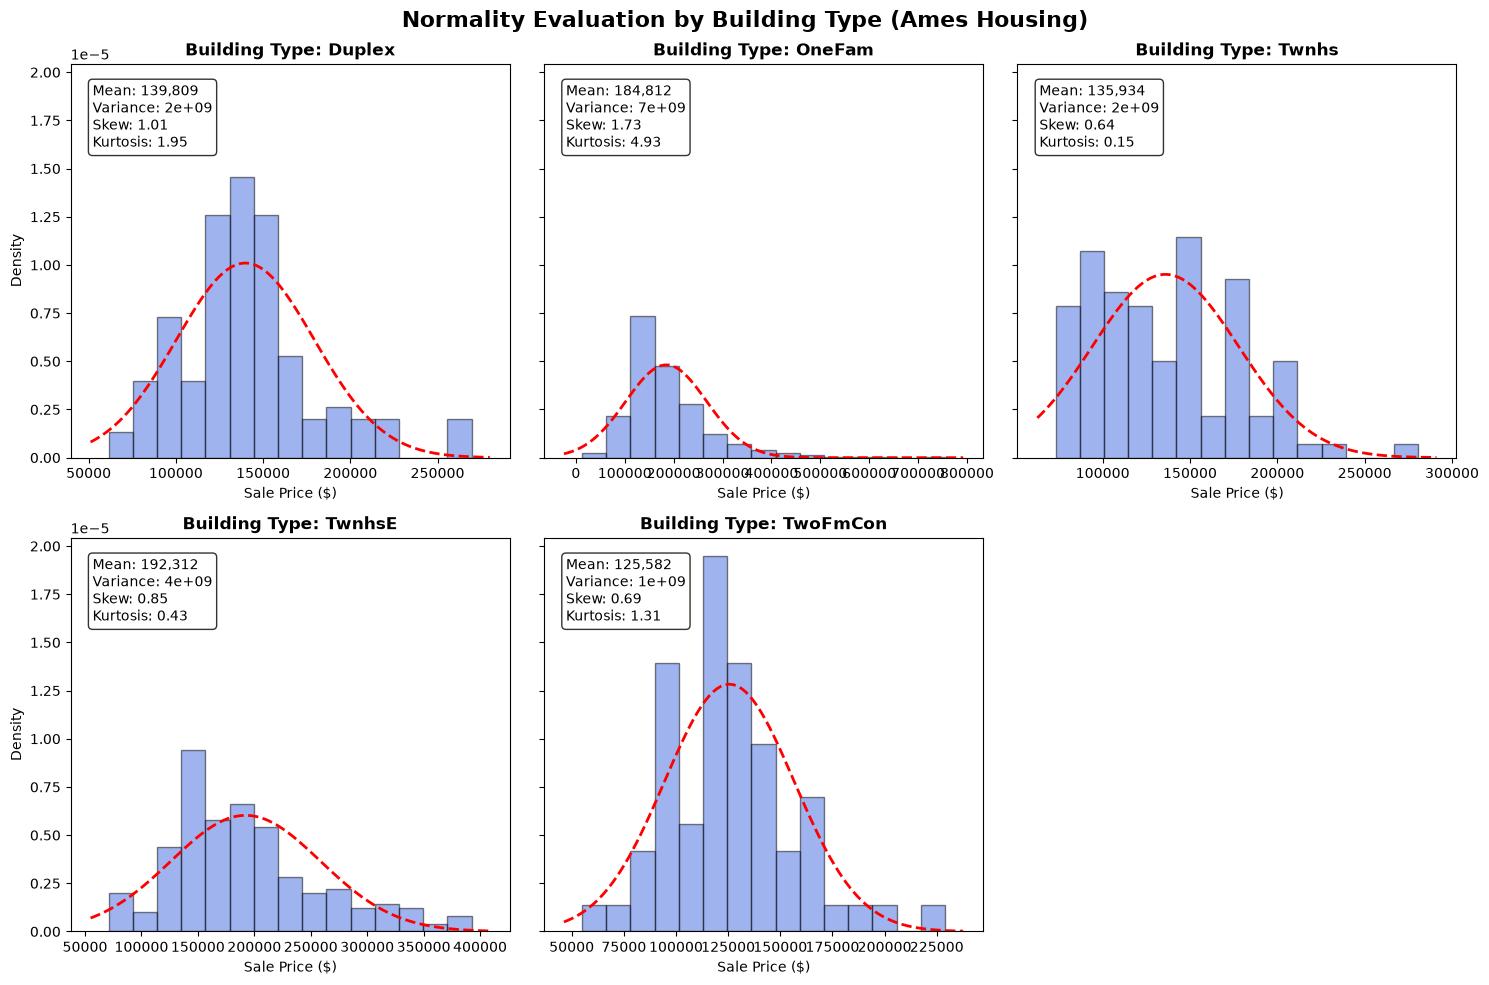

In [57]:
# 1. Corrected pandas aggregation
# (Fixes the typo and passes multiple aggregations as a list)
var_dist = ames.groupby('Bldg_Type')['Sale_Price'].agg(['mean', 'var'])
print("Aggregated Summary:")
print(var_dist)

# 2. Get the raw grouped object for iterating through actual values
grouped = ames.groupby('Bldg_Type')['Sale_Price']
groups = list(grouped)  # List of tuples: (group_name, group_series)
num_groups = len(groups) # This will be 5 based on Bldg_Type

# 3. Initialize a 2x3 grid to hold the 5 plots cleanly
nrows, ncols = 2, 3
fig, axes = plt.subplots(nrows=nrows, ncols=ncols, figsize=(15, 10), sharey=True)
axes_flat = axes.flatten()  # Flatten into a 1D array of 6 axes for easy looping

# 4. Loop through the 5 groups and plot
for i in range(nrows * ncols):
    ax = axes_flat[i]
    
    if i < num_groups:
        # Get data for the specific group
        group_name, group_data = groups[i]
        
        # Clean data: Drop missing values if any exist
        group_data = group_data.dropna()
        
        # Plot the group's density histogram
        ax.hist(group_data, bins=15, density=True, alpha=0.5, color='royalblue', edgecolor='black')
        
        # Calculate normal distribution baseline parameters
        mu, var = group_data.mean(), group_data.var()
        std = np.sqrt(var)
        
        # Generate a theoretical normal curve overlay
        xmin, xmax = ax.get_xlim()
        x = np.linspace(xmin, xmax, 100)
        p = stats.norm.pdf(x, mu, std)
        ax.plot(x, p, 'r--', linewidth=2, label='Normal Distribution')
        
        # Compute specific normality shape metrics
        skew = group_data.skew()
        kurt = group_data.kurt()  # Excess kurtosis (0 is normal)
        
        # Display the metrics in a text box inside the plot window
        textstr = f'Mean: {mu:,.0f}\nVariance: {var:,.0e}\nSkew: {skew:.2f}\nKurtosis: {kurt:.2f}'
        ax.text(0.05, 0.95, textstr, transform=ax.transAxes, fontsize=10,
                verticalalignment='top', bbox=dict(boxstyle='round', facecolor='white', alpha=0.8))
        
        # Subplot Polish
        ax.set_title(f'Building Type: {group_name}', fontsize=12, fontweight='bold')
        ax.set_xlabel('Sale Price ($)')
        if i % ncols == 0:
            ax.set_ylabel('Density')
            
    else:
        # Turn off the empty 6th subplot frame entirely
        ax.axis('off')

# Global figure title and spacing adjustment
plt.suptitle('Normality Evaluation by Building Type (Ames Housing)', fontsize=16, fontweight='bold', y=0.98)
plt.tight_layout()
plt.show()

**Equal variance**
* The largest variance is one family homes while the smallest is two family conversions. The standard deviations run from about 31k (TwoFmCon) to 83k (OneFam), a ratio of about 2.7, which is above the usual rule of thumb of 2. Levene's test agrees (p = 1.5e-12; its null is that all variances are equal, so a small p-value means the assumption is violated). Unequal variance is the real concern here.
* Group size is not why the variances differ. With `ddof=1`, a sample variance is unbiased at every n (see section 2), so a bigger group doesn't produce a bigger variance on average. OneFam is large because one family homes are a genuinely varied group (small cottages up to mansions). Small groups like TwoFmCon (62 houses) have noisier variance estimates, not systematically smaller ones.

**Normality**
* By skew and excess kurtosis, the least normal group is **OneFam** (skew 1.73, kurtosis 4.93: right-skewed, heavy tails). Duplex is next (1.01, 1.95), then TwnhsE (0.85, 0.43), TwoFmCon (0.69, 1.31) and Twnhs (0.64, 0.15). Twnhs is actually the closest to normal; its histogram lacking a central peak is a small-sample effect (101 houses), not real non-normality.
* Larger groups forgive non-normality because of the central limit theorem: the *means* of large groups are approximately normal even when the raw data are skewed, and ANOVA compares means. So OneFam's skew (n = 2,425) matters less than it looks.

**Permutation check**
* The permutation test and `f_oneway` agreed on F and p, but with F = 26 and p of about 1e-21 almost any test would agree, so this is weak evidence that the assumptions are fine. The permutation test also isn't assumption-free: it assumes the groups have the same distribution under the null, including the same variance.

**Conclusion**
* The normality concern is modest (the skewed group is large). The unequal variance is the real concern. The result is still robust here, given how extreme the p-value is, and a test that doesn't assume equal variances or normality agrees (`scipy.stats.kruskal`, p = 7e-31). If the p-value were borderline, I would switch to Welch's ANOVA or Kruskal-Wallis.

## 4. Two-Way ANOVA

One-way ANOVA has one grouping variable. Two-way ANOVA has two at once, and adds a new question: do the two factors *interact*? Numeric picture: suppose central air adds about $40k to a house in one building type, but only $5k in another. The "effect of central air" depends on building type. If the effect were the same $40k regardless, there'd be no interaction and the two factors would just add up.

Use `Sale_Price` with two factors. To keep every cell of the grid reasonably populated, restrict first: building types `OneFam`, `Duplex`, and `TwoFmCon`, crossed with `Central_Air` (Y/N). Start by looking at the count of houses in each cell (`pd.crosstab`) and the mean price in each cell.

1. Fit a model with both factors *and* their interaction (`smf.ols("Sale_Price ~ C(Bldg_Type) * C(Central_Air)", ...)`) and get the ANOVA table with `sm.stats.anova_lm`. Which rows are significant?
2. Draw an interaction plot (mean price by `Bldg_Type`, one line per `Central_Air` level). Do the lines look parallel? What does parallel vs. non-parallel mean for the interaction row of the table?
3. Why is the answer to "does central air matter?" potentially *incomplete* if you only read the main-effect row?
4. Refit without the interaction term. How do the other rows change, and when would you be justified in dropping it?

In [54]:
two_way_df = ames[ames["Bldg_Type"].isin(["OneFam","Duplex","TwoFmCon"])]
model = smf.ols("Sale_Price ~ Bldg_Type * Central_Air", data = two_way_df)
result = model.fit()

print(result.summary())

                            OLS Regression Results                            
Dep. Variable:             Sale_Price   R-squared:                       0.091
Model:                            OLS   Adj. R-squared:                  0.089
Method:                 Least Squares   F-statistic:                     51.77
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           2.62e-51
Time:                        14:53:28   Log-Likelihood:                -32918.
No. Observations:                2596   AIC:                         6.585e+04
Df Residuals:                    2590   BIC:                         6.588e+04
Df Model:                           5                                         
Covariance Type:            nonrobust                                         
                                             coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------------------------------

In [56]:
model = smf.ols("Sale_Price ~ C(Bldg_Type) * C(Central_Air)", data = two_way_df).fit()
anova_table = sm.stats.anova_lm(model, typ=2)
print(anova_table)

                                   sum_sq      df           F        PR(>F)
C(Bldg_Type)                 1.383050e+11     2.0   11.410791  1.164293e-05
C(Central_Air)               1.072276e+12     1.0  176.935301  4.211197e-39
C(Bldg_Type):C(Central_Air)  8.638093e+10     2.0    7.126817  8.191212e-04
Residual                     1.569611e+13  2590.0         NaN           NaN


**OLS Result Interpretation**
* With an interaction in the model, each coefficient is measured against a **reference group: Duplex with no central air**. The intercept (about 105,000) is that group's mean price.
* `Central_Air[T.Y]` (+45,150, p = 0.011) is the effect of central air **for Duplex only**, not the overall effect of central air. Each building type has its own effect, so there is no single overall coefficient in this model.
* `Bldg_Type[T.OneFam]:Central_Air[T.Y]` (+45,680, p = 0.016) is how much *more* central air is worth in a one family home than in a duplex. That is significant.
* `Bldg_Type[T.TwoFmCon]:Central_Air[T.Y]` (-20,610, p = 0.44) is not distinguishable from the duplex effect. That doesn't mean building type is irrelevant; it means the central air effect for TwoFmCon isn't shown to differ from Duplex's. There are only 28 and 34 houses in the TwoFmCon cells, so this test has little power.
* **Correct sum for a one family home with central air:** 105,000 (intercept) - 5,676 (one family main effect) + 45,150 (central air) + 45,680 (interaction) = about 190,170. This matches the actual cell mean (about 190,168). My earlier sum of 195,830 left out the one family main effect.
* Central air effect by type: Duplex about +45k, OneFam about +91k (45,150 + 45,680), TwoFmCon about +25k (45,150 - 20,610).
* The coefficient table tests each coefficient against the reference group. The per-factor tests come from `sm.stats.anova_lm(model, typ=2)`:
  * Central_Air: F = 176.9, p = 4e-39. Significant.
  * Bldg_Type: F = 11.4, p = 1e-5. Significant.
  * Bldg_Type x Central_Air (interaction): F = 7.13, p = 0.0008 with 2 df, because it tests both interaction coefficients together. Significant, so the central air effect really does differ by building type, even though one of the two interaction coefficients (TwoFmCon) was not significant on its own.
* Why the Bldg_Type F here (11.4) is smaller than a one-way ANOVA on Bldg_Type alone would give: the data are unbalanced (almost all OneFam houses have central air, but Duplex and TwoFmCon are mixed). `typ=2` tests Bldg_Type after accounting for Central_Air, whereas `typ=1` tests it first and credits it with whatever central air explains through its link to building type. With balanced data the two agree.


**ANOVA Table Interpretation**
* while ols shows to drop certain variables. ANOVA indicates that building type, central air, and their interaction are all statistically signficant.

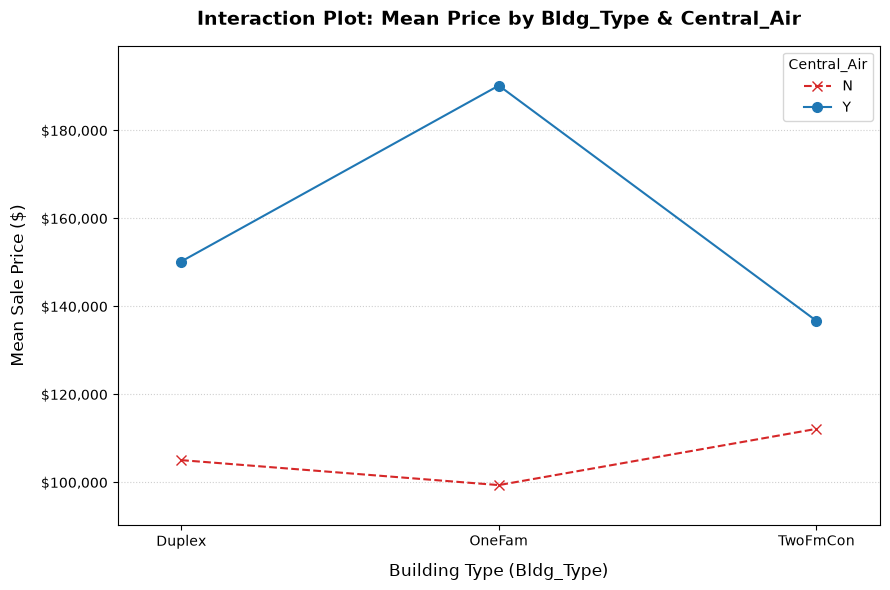

In [47]:
# Interaction plot
from statsmodels.graphics.factorplots import interaction_plot

# Assuming your DataFrame is named 'df'
fig, ax = plt.subplots(figsize=(9, 6))

interaction_plot(
    x=two_way_df['Bldg_Type'],       # X-axis factor
    trace=two_way_df['Central_Air'], # Separate line for each level ('Y' vs 'N')
    response=two_way_df['Sale_Price'],    # Continuous variable to average out
    colors=['#d62728', '#1f77b4'], # Red for 'N', Blue for 'Y'
    markers=['x', 'o'],      # Custom markers for each trace
    ms=7,                    # Marker size
    linestyles=['--', '-'],  # Dashed for 'N', Solid for 'Y'
    ax=ax
)

# Customizing layout to match standard real estate visuals
ax.set_title("Interaction Plot: Mean Price by Bldg_Type & Central_Air", fontsize=14, fontweight='bold', pad=15)
ax.set_xlabel("Building Type (Bldg_Type)", fontsize=12, labelpad=10)
ax.set_ylabel("Mean Sale Price ($)", fontsize=12, labelpad=10)

# Format y-axis values as currency with commas
ax.get_yaxis().set_major_formatter(plt.FuncFormatter(lambda x, loc: f"${x:,.0f}"))
ax.grid(axis='y', linestyle=':', alpha=0.6)

plt.tight_layout()
plt.show()

* The lines in the interaction plot are **not parallel**: the "Y" (central air) line rises steeply for one family homes, while the "N" line stays roughly flat at about 100-112k. Non-parallel lines are what an interaction looks like: the effect of central air depends on building type. If the lines were parallel, the interaction row of the ANOVA table would be near zero. The plot shows means, though, not significance. Whether the interaction is significant comes from the table.
* Reading only the main effect row for central air will tell you that it matters, but that answer is incomplete: it doesn't tell you *how much* it matters for a specific home type. Here it is roughly +45k for a duplex, +91k for a one family home and +25k for a two family conversion, which is the purpose of the interaction term.
* A non-significant interaction coefficient does **not** mean the home type is irrelevant. It means the central air effect for that type isn't shown to differ from the reference type's effect. Building type can still matter through its own main effect.

In [48]:
# drop interaction terms
model = smf.ols("Sale_Price ~ Bldg_Type + Central_Air", data = two_way_df)
result = model.fit()

print(result.summary())

                            OLS Regression Results                            
Dep. Variable:             Sale_Price   R-squared:                       0.086
Model:                            OLS   Adj. R-squared:                  0.085
Method:                 Least Squares   F-statistic:                     81.14
Date:                Sat, 03 Oct 2026   Prob (F-statistic):           3.59e-50
Time:                        14:44:57   Log-Likelihood:                -32925.
No. Observations:                2596   AIC:                         6.586e+04
Df Residuals:                    2592   BIC:                         6.588e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                            coef    std err          t      P>|t|      [0.025      0.975]
-----------------------------------------------------------------------------------------
Intercept              7.846e+

* Without the interaction term there is a single central air coefficient (about +79.6k), which is an **average** effect across all building types. It's weighted heavily toward one family homes because 2,282 of the 2,400 houses with central air are one family. So it overstates the effect for Duplex (about 45k) and TwoFmCon (about 25k) and understates it for OneFam (about 91k). "Inflated" isn't the right word: it's an average that hides the differences between types.
* The other coefficients change too. For example `Bldg_Type[T.OneFam]` goes from -5.7k (not significant) to +31k (significant), because without the interaction it averages over central air status instead of being measured only for houses without central air. The intercept also changes meaning: it is now a fitted value from the additive model, no longer the Duplex-without-AC cell mean.
* Fit also drops slightly (R-squared 0.091 to 0.086, adjusted 0.089 to 0.085).
* Dropping the interaction is justified when its test is not significant **and** there is no substantive reason to expect the effect to differ by group. Judge it with the joint test (the interaction row of `anova_lm`), not by a single coefficient. In this data the interaction row of the ANOVA table is significant (F = 7.13, p = 0.0008), so keep the interaction: dropping it would force a single central air effect on groups where it clearly differs (about +25k to +91k). The AIC also prefers the interaction model (about 65,850 vs 65,860).